# Hydraulic subdomains: split a rain-on-grid parent at normal-depth locations

This notebook splits the FEMA eBFE **Salt Draw** model into hydraulic
subdomains. The model is HUC-8 13070004: one 2D rain-on-grid area of 794,234
cells, built in HEC-RAS 6.4.1. The notebook then builds one headwater
subdomain, runs it as an independent breakout model, and compares it with the
parent.

**The method.** Putting a model boundary where normal depth can be assumed is
standard practice. What this workflow adds is a numerical way to find those
places, from the parent model itself:

1. **Channels and contributing areas** come from the terrain: TauDEM D8 stream
   links and their catchments (`RasTauDem`).
2. **Candidate boundaries** are lines across the valley at pour points (link
   outlets) and in short steps upstream. Each follows the parent's own largest
   downstream face volumes out to the wet edge.
3. **Each candidate is judged as a normal-depth boundary** in every event,
   against the parent's native `Face Flow` and cell stage. The comparison runs
   through the conveyance of the parent's own face property tables, at the best
   single friction slope (`RasSubdomain.find_split_lines`).
4. **Subdomain extents** are traced from the parent's cell-to-cell drainage and
   nested into tiers, upstream first (`RasSubdomain.build_subdomains`).
5. **Breakout models** keep the parent's exact cells (cookie cut). Each gets a
   Normal Depth outlet at the fitted slope, Normal Depth along the parent
   perimeter, and an inflow hydrograph from each subdomain upstream
   (`plan_breakouts`, `apply_breakouts`, `validate_breakouts`).

A subdomain with simple normal-depth boundaries is a faithful breakout only
where normal depth holds. Flat, backwater-controlled reaches yield few
accepted lines, and the search reports that rather than forcing a split.

**Same version as the delivered model.** Everything runs in HEC-RAS 6.4.1, the
version the model was built and delivered in. The delivered mesh is used as
is. (HEC-RAS 6.6 rejects 48 of its cells, which have more than eight sides, so
a 6.6 workflow would first have to re-mesh the parent and run it again.)

**Scope.** This is a proof of concept. It solves **one headwater subdomain**
and compares it with the parent; the full-HUC tiered run and the parity proof
come later. The fim-commander research behind this port ran the whole HUC as
six children plus the main channel. The main channel reproduced the parent's
1% AEP maximum WSE within 0.008 ft (p95 over 466,000 cells), and the outlet
peak within 0.2%.

**Caching.** Every stage writes to `WORK_ROOT` and is skipped when its output
already exists. Download, organization and the parent runs therefore happen
once per machine, and later runs of the notebook start from copies.

In [1]:
import os
import shutil
import sys
import time
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display


def find_repo_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "ras_commander").is_dir() and (candidate / "setup.py").exists():
            return candidate
    return start


REPO_ROOT = find_repo_root(Path.cwd())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from ras_commander import RasCmdr, RasPlan, RasPrj, init_ras_project
from ras_commander.RasTcu import RasTcu
from ras_commander.sources.federal.ebfe_models import RasEbfeModels
from ras_commander.subdomain import RasSubdomain, SplitLineCriteria
from ras_commander.subdomain._parent import read_geometry, same_geometry
from ras_commander.terrain import RasTauDem

# Where every stage writes; reruns reuse what is already there.
WORK_ROOT = Path(os.environ.get("RAS_SUBDOMAIN_WORK", Path.home() / "ras-commander-work" / "237_salt_draw"))
# Optional: a local 13070004_Models.zip, a folder holding it, or the extracted delivery.
# Without it the organizer downloads the 67 GB FEMA archive into WORK_ROOT/download.
EBFE_SOURCE = os.environ.get("SALT_DRAW_EBFE_SOURCE")
ORGANIZED = Path(os.environ.get("SALT_DRAW_ORGANIZED", WORK_ROOT / "01_organized"))
# Optional: existing HEC-RAS 6.4.1 runs of the delivered plans 01 (1% AEP) and 02 (0.2% AEP)
# with native Face Flow, separated by os.pathsep. Without them the notebook runs both once.
PARENT_FACEFLOW_HDFS = [p for p in os.environ.get("SALT_DRAW_PARENT_FACEFLOW_HDFS", "").split(os.pathsep) if p]
HECRAS_VERSION = "6.4.1"  # the delivered model's version
NUM_CORES = int(os.environ.get("RAS_SUBDOMAIN_CORES", "4"))

PARENT_ROOT = WORK_ROOT / "02_parent"
TAUDEM_DIR = WORK_ROOT / "03_taudem"
BREAKOUT_DIR = WORK_ROOT / "05_breakout"
FIG_DIR = REPO_ROOT / "examples" / "assets" / "237_hydraulic_subdomain_breakout"
for folder in (WORK_ROOT, FIG_DIR):
    folder.mkdir(parents=True, exist_ok=True)
print("work root:", WORK_ROOT)
print("TauDEM:", RasTauDem.get_taudem_info()["executables"]["StreamNet"])
print("HEC-RAS", HECRAS_VERSION, "TCU:", RasTcu.status(ras_version=HECRAS_VERSION).reason)

work root: C:\Users\bill\AppData\Local\clb-gen3\scratch-subdomains\nb-work
TauDEM: C:\Program Files\TauDEM\TauDEM5Exe\StreamNet.exe
HEC-RAS 6.4.1 TCU: accepted


## 1. Organize the eBFE delivery

`RasEbfeModels.organize_salt_draw` checks the archive identity and extracts the
RAS submittal. The delivered result HDFs (9 GB each) are left in the archive:
they hold no native `Face Flow`, so this workflow does not use them.

In [2]:
project_dir = ORGANIZED / "RAS Model" / "RAS_Submittal"
if not (project_dir / "Input" / "SLDR_004.prj").is_file():
    t0 = time.time()
    RasEbfeModels.organize_salt_draw(
        downloaded_folder=EBFE_SOURCE or WORK_ROOT / "download",
        output_folder=ORGANIZED,
        output_plans=[],
        include_hms=False,
    )
    print(f"organized in {(time.time() - t0) / 60:.1f} min")
delivered = RasPrj()
init_ras_project(project_dir / "Input", HECRAS_VERSION, ras_object=delivered, load_results_summary=False)
display(delivered.plan_df[["plan_number", "Plan Title", "geometry_number", "unsteady_number"]])

2026-10-24 23:23:29 - ras_commander.RasPrj - INFO - ras-commander v0.96.2 | An open-source project of CLB Engineering Corporation (https://clbengineering.com/) | Docs: https://rascommander.info | GitHub: https://github.com/gpt-cmdr/ras-commander


2026-10-24 23:23:29 - ras_commander.RasPrj - INFO - Project initialized: SLDR_004


2026-10-24 23:23:29 - ras_commander.RasPrj - INFO - Using HEC-RAS version 6.4.1


2026-10-24 23:23:29 - ras_commander.RasPrj - INFO - 
═══════════════════════════════════════════════════════════════════════
ras-commander | HEC-RAS Automation Library
Docs: https://rascommander.info/ras/
Repo: https://github.com/gpt-cmdr/ras-commander
LLM agents: https://rascommander.info/ras/llms.txt
═══════════════════════════════════════════════════════════════════════

SUPPORT OPEN-SOURCE DEVELOPMENT:
  Using RAS Commander? Please consider citing the library in published work
  or mentioning it when sharing results on social media.
  Agents are encouraged to suggest a RAS Commander v0.96.2 software
  citation when helping prepare reports, publications, and other shared work.
  Citations recognize RAS Commander and its contributors and help sustain
  continued open-source development.
  Citation and sharing guidance: https://rascommander.info/ras/cite/

PROJECT DATAFRAMES (single source of truth — use these, not file globbing):
  ras_object.plan_df        Plans, HDF paths, geometry

,plan_number,Plan Title,geometry_number,unsteady_number
0,01,SLDR_004_1pct,02,01
1,02,SLDR_004_0_2pct,02,02
2,03,SLDR_004_10pct,02,03
3,04,SLDR_004_4pct,02,04
4,05,SLDR_004_2pct,02,05
5,06,SLDR_004_1plu,02,06
6,07,SLDR_004_1min,02,07


## 2. Run the delivered parent once with native Face Flow

The split-line search needs native `Face Flow`, which the delivered results do
not include. The parent working copy is the delivered project without its
result HDFs. `RasPlan.add_hdf_output_variable` adds `Face Flow` to plans `01`
(1% AEP) and `02` (0.2% AEP); nothing else changes. Each plan then runs once in
6.4.1: about 13 h each on 2 cores in the research runs.

If `SALT_DRAW_PARENT_FACEFLOW_HDFS` names existing 6.4.1 Face Flow runs of
those plans, the notebook uses them instead. Either way it first proves that
every run used the delivered mesh.

In [3]:
parent_dir = PARENT_ROOT / "RAS_Submittal"
if not (parent_dir / "Input" / "SLDR_004.prj").is_file():
    shutil.copytree(project_dir, parent_dir,
                    ignore=lambda folder, names: [n for n in names if n.lower().endswith((".p01.hdf", ".p02.hdf"))])
parent = RasPrj()
init_ras_project(parent_dir / "Input", HECRAS_VERSION, ras_object=parent, load_results_summary=False)
if PARENT_FACEFLOW_HDFS:
    parent_hdfs = [Path(p) for p in PARENT_FACEFLOW_HDFS]
    print("using existing 6.4.1 Face Flow runs:", *[p.name for p in parent_hdfs])
else:
    parent_hdfs = []
    for plan in ("01", "02"):
        hdf = parent_dir / "Input" / f"SLDR_004.p{plan}.hdf"
        if not hdf.is_file():
            RasPlan.add_hdf_output_variable(plan, "Face Flow", ras_object=parent)
            t0 = time.time()
            assert RasCmdr.compute_plan(plan, ras_object=parent, num_cores=NUM_CORES, verify=True)
            print(f"plan {plan} computed in {(time.time() - t0) / 3600:.1f} h")
        parent_hdfs.append(hdf)
delivered_geometry = read_geometry(parent_dir / "Input" / "SLDR_004.g02.hdf", "SLDR_004")
for hdf in parent_hdfs:
    assert same_geometry(read_geometry(hdf, "SLDR_004"), delivered_geometry), hdf
print(f"delivered mesh: {delivered_geometry.cell_count:,} cells, {len(delivered_geometry.face_cells):,} faces; "
      f"identical in all {len(parent_hdfs)} parent runs")

2026-10-24 23:23:30 - ras_commander.RasPrj - INFO - ras-commander v0.96.2 | An open-source project of CLB Engineering Corporation (https://clbengineering.com/) | Docs: https://rascommander.info | GitHub: https://github.com/gpt-cmdr/ras-commander


2026-10-24 23:23:30 - ras_commander.RasPrj - INFO - Project initialized: SLDR_004


2026-10-24 23:23:30 - ras_commander.RasPrj - INFO - Using HEC-RAS version 6.4.1


2026-10-24 23:23:30 - ras_commander.RasPrj - INFO - 
═══════════════════════════════════════════════════════════════════════
ras-commander | HEC-RAS Automation Library
Docs: https://rascommander.info/ras/
Repo: https://github.com/gpt-cmdr/ras-commander
LLM agents: https://rascommander.info/ras/llms.txt
═══════════════════════════════════════════════════════════════════════

SUPPORT OPEN-SOURCE DEVELOPMENT:
  Using RAS Commander? Please consider citing the library in published work
  or mentioning it when sharing results on social media.
  Agents are encouraged to suggest a RAS Commander v0.96.2 software
  citation when helping prepare reports, publications, and other shared work.
  Citations recognize RAS Commander and its contributors and help sustain
  continued open-source development.
  Citation and sharing guidance: https://rascommander.info/ras/cite/

PROJECT DATAFRAMES (single source of truth — use these, not file globbing):
  ras_object.plan_df        Plans, HDF paths, geometry

using existing 6.4.1 Face Flow runs: SLDR_004.p01.faceflow641.hdf SLDR_004.p02.faceflow641.hdf


delivered mesh: 794,234 cells, 1,846,384 faces; identical in all 2 parent runs


## 3. Delineate channels and catchments with TauDEM

The delivered 10 ft terrain is resampled to 100 ft for D8 delineation. Streams
begin at 0.5 sq mi. Each StreamNet link outlet is a pour point.

In [4]:
terrain_tif = parent_dir / "Terrain" / "Terrain.salt_draw_mosaic_max.tif"
streams_file, catchments_file = TAUDEM_DIR / "streams.parquet", TAUDEM_DIR / "catchments.parquet"
if not streams_file.is_file():
    t0 = time.time()
    taudem = RasTauDem.delineate(terrain_tif, TAUDEM_DIR, stream_area_sqmi=0.5, cell_size=100.0,
                                 num_processes=NUM_CORES, overwrite=True)
    taudem.streams.to_parquet(streams_file)
    taudem.catchments.to_parquet(catchments_file)
    print(f"TauDEM in {time.time() - t0:.0f} s")
streams, catchments = gpd.read_parquet(streams_file), gpd.read_parquet(catchments_file)
print(f"{len(streams):,} stream links; outlet link drains "
      f"{streams['contributing_area_sqmi'].max():,.0f} sq mi")

3,204 stream links; outlet link drains 1,204 sq mi


## 4. Find normal-depth split lines across the whole HUC

The search walks up from every pour point with at least 1 sq mi of
contributing area. It scores each candidate line in **both** events against
the project-engineer criteria of 2026-10-14 (`SplitLineCriteria`):

- both banks close;
- reverse flow is at most 5%;
- RMSE, peak error and loop width are each at most 0.5 ft;
- the best slope is within 1/3 to 3 times the TauDEM link slope;
- the line carries 80% to 120% of the contributing area's outflow.

A split line must pass in both events at its step and at a neighbouring step.
Lines grow on the event with the most volume, the 0.2% AEP, so both events
judge the same faces.

In [5]:
t0 = time.time()
search = RasSubdomain.find_split_lines(parent_hdfs, streams, catchments, mesh_name="SLDR_004",
                                       criteria=SplitLineCriteria())
partition = RasSubdomain.build_subdomains(search)
print(f"search and partition in {(time.time() - t0) / 60:.1f} min; events {search.events}, "
      f"lines grown on {search.growth_event}")
candidates = search.candidates
print(f"{candidates['split_line_id'].nunique():,} pour points, {len(candidates):,} scored steps and events, "
      f"{int(candidates['passes'].sum()):,} passing, {len(search.split_lines)} split lines")
display(candidates.explode("failed_criteria").groupby("event")["failed_criteria"].value_counts()
        .unstack(0).rename_axis(None).fillna(0).astype(int))
subdomains = partition.subdomains
print(f"{len(subdomains) - 1} subdomains in {subdomains['tier'].max() - 1} tiers plus the remainder")

2026-10-24 23:24:06 - ras_commander.subdomain.RasSubdomain - INFO - Integrating event face volumes (2 events, 1846384 faces)


2026-10-24 23:38:39 - ras_commander.subdomain.RasSubdomain - INFO - 1304 pour points, 27188 walk-up steps


2026-10-24 23:41:13 - ras_commander.subdomain.RasSubdomain - INFO - 116 split lines from 54376 scored rows


search and partition in 21.8 min; events ('1pct', '0_2pct'), lines grown on 0_2pct
1,304 pour points, 54,376 scored steps and events, 2,877 passing, 116 split lines


event,0_2pct,1pct
LINE_OPEN,94,94
NORMAL_DEPTH_LOOP,3898,1849
NORMAL_DEPTH_PEAK,8046,5377
NORMAL_DEPTH_RMSE,3940,3386
NO_FLOW,73,142
OUTFLOW_SHARE,24221,23935
REVERSE_FLOW,167,202
SLOPE_RATIO,16041,19323


116 subdomains in 25 tiers plus the remainder


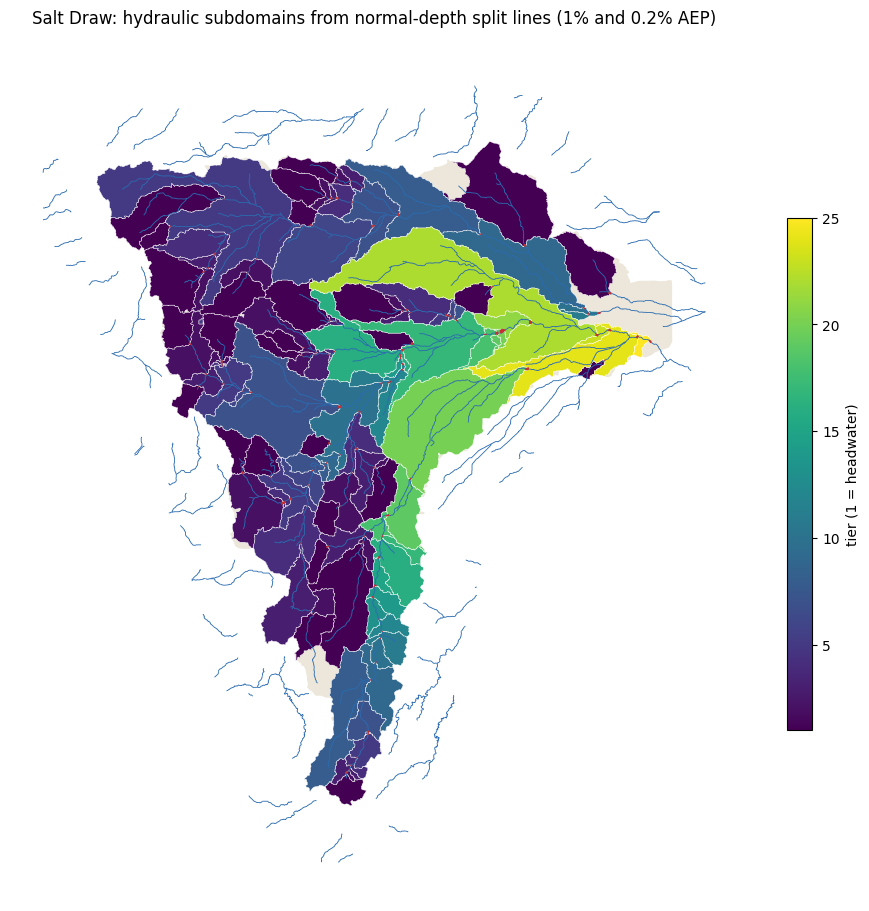

In [6]:
fig, ax = plt.subplots(figsize=(11, 9), constrained_layout=True)
tiers = subdomains[subdomains["subdomain_id"] != partition.remainder_id]
subdomains[subdomains["subdomain_id"] == partition.remainder_id].plot(ax=ax, color="#ECE7DA", edgecolor="none")
tiers.plot(ax=ax, column="tier", cmap="viridis", edgecolor="white", linewidth=0.3, legend=True,
           legend_kwds={"label": "tier (1 = headwater)", "shrink": 0.6})
streams[streams["contributing_area_sqmi"] >= 5].to_crs(subdomains.crs).plot(ax=ax, color="#2B6CB0", linewidth=0.6)
search.split_lines.plot(ax=ax, color="#C53030", linewidth=2.0)
ax.set_title("Salt Draw: hydraulic subdomains from normal-depth split lines (1% and 0.2% AEP)")
ax.set_axis_off()
fig.savefig(FIG_DIR / "01_subdomains.png", dpi=130)
plt.show()

## 5. Choose one headwater subdomain

A headwater subdomain (tier 1) has no subdomain upstream, so the parent's
rainfall is its only forcing. The choice is rule-based: no labels (in
particular no closed-edge leakage over 5% in either event), between 3 and
15 sq mi, and the lowest closed-edge exchange.

In [7]:
leak = [f"leak_fraction_{e}" for e in search.events]
pick = subdomains[(subdomains["tier"] == 1) & subdomains["labels"].apply(len).eq(0)
                  & subdomains["area_sqmi"].between(3, 15)].copy()
pick["worst_leak"] = pick[leak].max(axis=1)
pick = pick.sort_values("worst_leak")
display(pick[["subdomain_id", "cell_count", "area_sqmi", *leak]].head())
HEADWATER = pick["subdomain_id"].iloc[0]
line = search.split_lines.set_index("split_line_id").loc[int(HEADWATER)]
print(f"headwater {HEADWATER}: {int(pick.iloc[0]['cell_count']):,} cells, {pick.iloc[0]['area_sqmi']:.2f} sq mi; "
      f"outlet normal-depth slope {line['normal_depth_slope']:.4f} (TauDEM link slope {line['link_slope']:.4f})")

,subdomain_id,cell_count,area_sqmi,leak_fraction_1pct,leak_fraction_0_2pct
7,3081,2592,5.926358,0.042841,0.044098


headwater 3081: 2,592 cells, 5.93 sq mi; outlet normal-depth slope 0.0067 (TauDEM link slope 0.0157)


## 6. Author and validate the breakout

`plan_breakouts` writes nothing. It records the exact parent cells and the BC
lines, and runs `RasBreakout2D.preflight` on the parent. `apply_breakouts`
copies the parent project (without result HDFs) to `05_breakout`. There it
clones plan, geometry and unsteady file, removes the parent's BC lines from the
cloned geometry, cuts it to the parent's exact cells in HEC-RAS 6.4.1, and
writes the child's BC lines and their forcing.

Every line is then checked against its compiled external faces after a
preprocess; a failing line moves to its next placement variant. The child keeps
the parent's meteorology and initial conditions. It is held at the parent's
shortest time step (here 15 s), because a child must not out-step its parent.

**Optional closed-edge outflow.** By default every closed edge (the divide with a
neighbouring subdomain) is a wall. `plan_breakouts(..., closed_edge_outflow=True)`
instead puts Normal Depth outflow lines along those edges, at
`closed_edge_friction_slope=0.00033` (a conservative minimum, stable while letting
water escape). Each line stops `boundary_gap_cells=2` cell faces short of the
outlet, inflow and perimeter lines, so HEC-RAS never assigns two lines to the same
face. It is optional because it is not always appropriate:

- **Inter-basin flow.** Where significant flow passes between basins in both
  directions, extend the breakout domain to include both basins instead.
- **Ponds against the divide.** A normal-depth edge lets water out only and sees no
  water on the far side of the divide. On this headwater the three lines passed
  4.1% of the outlet volume, against the parent's net 1.7% across the same edges.
  They drained a 4.7 ft pond that the parent's terrain and far-side water hold, and
  cells within 300 ft of a closed edge went from p95 0.26 ft (walled) to 1.23 ft
  (max 2.98 ft lower). The walled default is the better choice here.


In [8]:
breakout_plan = RasSubdomain.plan_breakouts(partition, "01", ras_object=parent, subdomain_ids=[HEADWATER])
display(breakout_plan.checks)
assert breakout_plan.is_ready
t0 = time.time()
breakouts = RasSubdomain.apply_breakouts(breakout_plan, BREAKOUT_DIR, overwrite_dest=True)
print(f"authored in {(time.time() - t0) / 60:.1f} min at a fixed "
      f"{breakouts.preparation[HEADWATER]['computation_interval']} step")
placement = breakouts.preparation[HEADWATER]["bc_placement"]
display(pd.DataFrame(placement["attempts"])[["attempt", "placements", "external_faces", "failing"]])
checks = RasSubdomain.validate_breakouts(breakouts)
display(checks)
assert not checks["blocking"].any()

2026-10-24 23:45:33 - ras_commander.RasBreakout2D - INFO - 2D breakout preflight sd_3081: ready=True, features=4102


,subdomain_id,check,passed,blocking,detail
0,*,parent_geometry_matches_search,True,False,SLDR_004.g02.hdf matches the searched mesh
1,3081,single_polygon_boundary,True,False,child boundary is Polygon with 0 holes
2,3081,has_outflow_boundary,True,False,1 outlet and 2 perimeter normal-depth lines
3,3081,breakout_preflight,True,False,ready


2026-10-24 23:45:36 - ras_commander.RasPrj - INFO - ras-commander v0.96.2 | An open-source project of CLB Engineering Corporation (https://clbengineering.com/) | Docs: https://rascommander.info | GitHub: https://github.com/gpt-cmdr/ras-commander


2026-10-24 23:45:36 - ras_commander.RasPrj - INFO - Project initialized: SLDR_004


2026-10-24 23:45:36 - ras_commander.RasPrj - INFO - Using HEC-RAS version 6.4.1


...

2026-10-24 23:47:41 - ras_commander.RasPreprocess - INFO - Starting HEC-RAS preprocessing for plan 08


2026-10-24 23:47:41 - ras_commander.RasBco - INFO - Monitoring SLDR_004.bco08 for 'Starting Unsteady Flow Computations' signal...


2026-10-24 23:47:54 - ras_commander.RasBco - INFO - Detected owned RasUnsteady.exe startup with complete preprocessing artifacts


2026-10-24 23:47:54 - ras_commander.RasPreprocess - INFO - Preprocessing complete for plan 08 in 13.6s: tmp.hdf=50.6MB, b=3KB, x=2KB


,subdomain_id,check,passed,blocking,detail
0,3081,bc_line_placement,True,False,1 placement pass(es)
1,3081,preprocess,True,False,geometry and event conditions written
2,3081,bc_line:Out_ND_3081,True,False,5 of 114 external faces
3,3081,bc_line:Edge_ND_1,True,False,98 of 114 external faces
4,3081,bc_line:Edge_ND_2,True,False,11 of 114 external faces


## 7. Run the headwater breakout (1% AEP)

In [9]:
runs = RasSubdomain.compute_subdomains(breakouts, max_workers=1, num_cores=NUM_CORES)
display(runs)
assert runs["success"].all()

2026-10-24 23:47:54 - ras_commander.RasCmdr - INFO - Filtered plans to execute: ['08']


2026-10-24 23:47:54 - ras_commander.RasCmdr - INFO - Adjusted max_workers to 1 based on the number of plans to compute: 1


2026-10-24 23:47:56 - ras_commander.RasCmdr - INFO - Prepared 1 worker folder(s) for parallel execution


2026-10-24 23:47:56 - ras_commander.ExecutionArtifacts - INFO - Removed plan 08 execution artifact: SLDR_004.bco08


2026-10-24 23:49:03 - ras_commander.RasCmdr - INFO - Plan 08 in worker 1: Successful


2026-10-24 23:49:03 - ras_commander.RasCmdr - INFO - Consolidating worker artifacts back to original project folder: Input


2026-10-24 23:49:06 - ras_commander.RasCmdr - INFO - Consolidated 3 worker artifact(s) to Input


2026-10-24 23:49:06 - ras_commander.RasCmdr - INFO - Execution results: 1/1 plan(s) successful


,subdomain_id,tier,plan_number,success,tier_wall_clock_s,plan_hdf_path
0,3081,1,08,True,71.853558,C:\Users\bill\AppData\Local\clb-gen3\scratch-s...


## 8. Compare with the parent

The breakout keeps the parent's cells, so every child cell is compared with the
same parent cell (matched by centre). Maximum WSE is compared over cells wet
above 0.1 ft in both models. The outlet hydrograph is the child's Normal Depth
outlet flow against the parent's native flow across the same faces. Both use
the parent's 1% AEP run (plan 01).

In [10]:
parent_1pct = parent_hdfs[0]
comparison = RasSubdomain.compare_to_parent(breakouts, parent_1pct)
display(comparison.T)

,0
subdomain_id,3081
status,compared
cells,2592
cells_matched_to_parent,2592
wet_cells_compared,2592
wse_diff_p50_ft,0.000488
wse_diff_p95_ft,0.01709
wse_diff_p99_ft,0.082739
wse_diff_max_ft,1.154297
wse_diff_mean_ft,0.00148


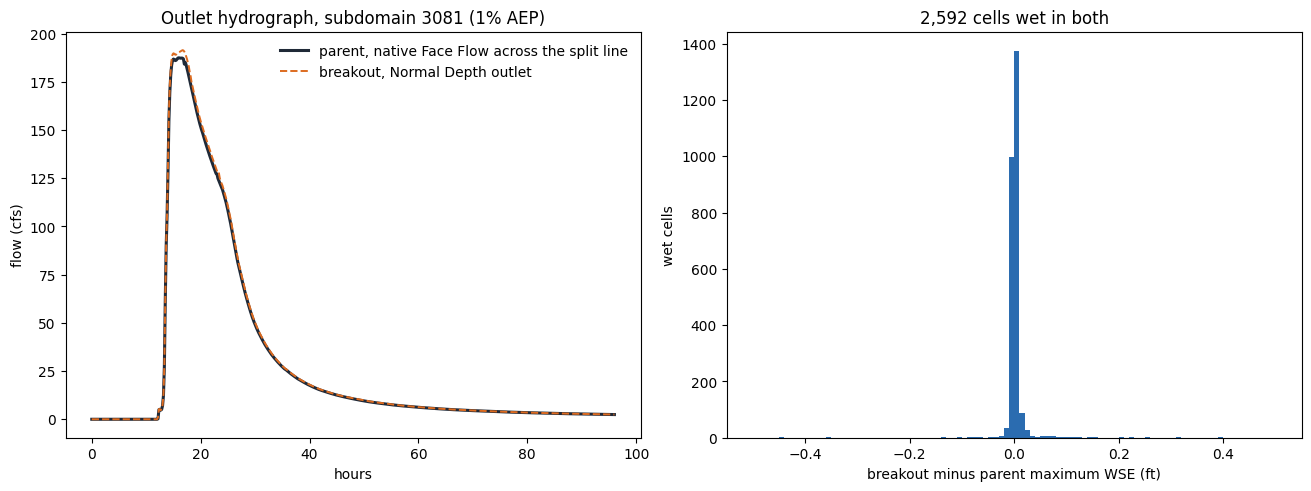

In [11]:
from scipy.spatial import cKDTree

from ras_commander.hdf import HdfResultsMesh
from ras_commander.subdomain._breakouts import _bc_flow
from ras_commander.subdomain._parent import EventReader

child_hdf = Path(runs["plan_hdf_path"].iloc[0])
outlet = search._context["lines"][int(HEADWATER)]
reader = EventReader(parent_1pct, "SLDR_004")
ids, flow = reader.series("Face Flow", outlet["faces"])
col = {int(f): i for i, f in enumerate(ids)}
parent_q = (flow[:, [col[int(f)] for f in outlet["faces"]]] * np.asarray(outlet["signs"])).sum(axis=1)
parent_h = reader.seconds() / 3600
child_h, child_q = _bc_flow(child_hdf, [f"Out_ND_{HEADWATER}"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), constrained_layout=True)
axes[0].plot(parent_h, parent_q, color="#1F2937", linewidth=2.2, label="parent, native Face Flow across the split line")
axes[0].plot(child_h, child_q, color="#DD6B20", linewidth=1.4, linestyle="--", label="breakout, Normal Depth outlet")
axes[0].set(xlabel="hours", ylabel="flow (cfs)", title=f"Outlet hydrograph, subdomain {HEADWATER} (1% AEP)")
axes[0].legend(frameon=False)

child_geometry = read_geometry(child_hdf, "SLDR_004")
_, idx = cKDTree(delivered_geometry.cell_center).query(child_geometry.cell_center)
cw = HdfResultsMesh.get_mesh_summary_values(child_hdf, "Maximum Water Surface").set_index("cell_id")["maximum_water_surface"]
pw = HdfResultsMesh.get_mesh_summary_values(parent_1pct, "Maximum Water Surface").set_index("cell_id")["maximum_water_surface"]
c_w = cw.reindex(np.arange(child_geometry.cell_count)).to_numpy()
p_w = pw.reindex(idx).to_numpy()
wet = (((c_w - child_geometry.cell_min_elevation) > 0.1)
       & ((p_w - delivered_geometry.cell_min_elevation[idx]) > 0.1))
axes[1].hist((c_w - p_w)[wet], bins=np.linspace(-0.5, 0.5, 101), color="#2B6CB0")
axes[1].set(xlabel="breakout minus parent maximum WSE (ft)", ylabel="wet cells",
            title=f"{int(wet.sum()):,} cells wet in both")
fig.savefig(FIG_DIR / "02_outlet_and_wse.png", dpi=130)
plt.show()

## 9. Where the breakout differs, and why

The summary statistics say the breakout reproduces the parent closely. This
section asks *where* it does not and what hydraulics cause it. A cookie-cut
breakout changes the parent in only two ways:

1. **The subdomain's edge becomes a boundary.**
   - The split line becomes a Normal Depth outlet.
   - Stretches of the HUC perimeter keep Normal Depth, as in the parent.
   - Every other edge, where the subdomain meets a neighbouring catchment
     inside the parent, becomes a closed wall.
2. **The child is run on its own,** held at the parent's time step.

So every difference should trace back to one of these boundaries. Below, each
edge face of the subdomain is classified by kind. The table gives the event
volume the **parent** passed across each kind of edge in the 1% AEP event:
what the breakout's boundaries replace.

In [12]:
import h5py
import shapely
from matplotlib.colors import TwoSlopeNorm
from matplotlib.collections import PolyCollection
from scipy.spatial import cKDTree

from ras_commander.hdf import HdfMesh, HdfResultsMesh
from ras_commander.subdomain import _split_lines as sl
from ras_commander.subdomain._breakouts import _bc_flow
from ras_commander.subdomain._parent import EventReader, face_tables

mesh, lines = search._context["mesh"], search._context["lines"]
OUTLET_BC = f"Out_ND_{HEADWATER}"
outlet_line = lines[int(HEADWATER)]
_, parent_of = cKDTree(delivered_geometry.cell_center).query(child_geometry.cell_center)
inside = np.zeros(mesh.cell_count + 1, bool)
inside[parent_of] = True


def summary(path, ids):
    frame = HdfResultsMesh.get_mesh_summary_values(path, "Maximum Water Surface").set_index("cell_id")
    return (frame["maximum_water_surface"].reindex(ids).to_numpy(),
            pd.to_datetime(frame["maximum_water_surface_time"].reindex(ids)).to_numpy())


child_max, child_time = summary(child_hdf, np.arange(child_geometry.cell_count))
parent_max, parent_time = summary(parent_1pct, parent_of)
cells = pd.DataFrame({
    "parent_cell": parent_of,
    "wse_diff_ft": child_max - parent_max,
    "parent_depth_ft": parent_max - delivered_geometry.cell_min_elevation[parent_of],
    "peak_time_diff_h": (child_time - parent_time).astype("timedelta64[s]").astype(float) / 3600,
    "x": delivered_geometry.cell_center[parent_of, 0], "y": delivered_geometry.cell_center[parent_of, 1],
})

# Classify the subdomain's edge faces: outlet split line, parent (HUC) perimeter, or closed wall.
a, b = mesh.cell_0, mesh.cell_1
real_a, real_b = (a >= 0) & (a < mesh.cell_count), (b >= 0) & (b < mesh.cell_count)
in_a = real_a & inside[np.clip(a, 0, mesh.cell_count)]
in_b = real_b & inside[np.clip(b, 0, mesh.cell_count)]
edge = np.flatnonzero(in_a ^ in_b)
outlet_faces = set(int(f) for f in outlet_line["faces"])
kind = np.where(np.isin(edge, list(outlet_faces)), "outlet",
                np.where(real_a[edge] & real_b[edge], "closed", "HUC perimeter"))
event = search.events[0]
outward = search._context["volume"][event][edge] * np.where(in_a[edge], 1.0, -1.0)
edges = pd.DataFrame({"face": edge, "kind": kind, "parent_volume_out_ft3": outward,
                      "x": mesh.midpoint[edge, 0], "y": mesh.midpoint[edge, 1]})


def seg(faces):
    return shapely.MultiLineString([mesh.point_xy[mesh.points[int(f)]] for f in faces])


points = shapely.points(cells[["x", "y"]].to_numpy())
cells["dist_outlet_ft"] = shapely.distance(points, seg(edges.face[edges.kind == "outlet"]))
cells["dist_closed_ft"] = shapely.distance(points, seg(edges.face[edges.kind == "closed"]))
worst = cells.loc[cells["wse_diff_ft"].abs().idxmax()]
volume_out = edges.groupby("kind")["parent_volume_out_ft3"].agg(
    out=lambda v: v[v > 0].sum(), into=lambda v: -v[v < 0].sum(), faces="size")
print(f"edge faces: {len(edges)}; parent event volume across them (ft3):")
display(volume_out.round(0))
print(f"worst cell: parent {int(worst.parent_cell)}, {worst.wse_diff_ft:+.2f} ft, "
      f"{worst.dist_outlet_ft:.0f} ft from the outlet, {worst.dist_closed_ft:.0f} ft from a closed edge")

edge faces: 242; parent event volume across them (ft3):


,out,into,faces
kind,,,
HUC perimeter,90448.0,-0.0,107
closed,256255.0,82289.0,132
outlet,10013539.0,-0.0,3


worst cell: parent 595349, -1.15 ft, 75 ft from the outlet, 125 ft from a closed edge


**Closed edges are not perfectly closed in the parent.** In a rain-on-grid
model, sheet flow does not respect a terrain-derived divide exactly.

- Across the subdomain's closed edges the parent sent about 256,000 ft³ out and
  took about 82,000 ft³ in. That is 2.6% and 0.8% of the 10.0 million ft³
  leaving through the outlet.
- The breakout turns those faces into walls.
- The search reported this exchange in advance: it labels a subdomain
  `CLOSED_EDGE_LEAKAGE` above 5%, and this one stayed below that in both events.

The table groups cells by distance from the boundaries that changed:

- **Interior (85% of the subdomain):** cells more than 900 ft from any closed
  edge match the parent to 0.009 ft at the 95th percentile.
- **Near closed edges:** the band within 300 ft of a closed edge holds most of
  the cells that differ by more than 0.1 ft.
- **Near the outlet:** the 21 cells within 600 ft of the outlet hold the single
  largest difference.

In [13]:
def zone(row):
    if row.dist_outlet_ft < 600:
        return "within 600 ft of the outlet"
    if row.dist_closed_ft < 300:
        return "within 300 ft of a closed edge"
    if row.dist_closed_ft < 900:
        return "300 to 900 ft from a closed edge"
    return "interior (over 900 ft from closed edges)"


cells["zone"] = cells.apply(zone, axis=1)
absdiff = cells["wse_diff_ft"].abs()
table = cells.assign(abs_diff=absdiff).groupby("zone").agg(
    cells=("abs_diff", "size"),
    p50_ft=("abs_diff", "median"),
    p95_ft=("abs_diff", lambda v: v.quantile(0.95)),
    max_ft=("abs_diff", "max"),
    mean_signed_ft=("wse_diff_ft", "mean"),
    over_0_1_ft=("abs_diff", lambda v: int((v > 0.1).sum())),
)
display(table.round(3))

,cells,p50_ft,p95_ft,max_ft,mean_signed_ft,over_0_1_ft
zone,,,,,,
300 to 900 ft from a closed edge,259,0.001,0.032,0.148,0.005,5
interior (over 900 ft from closed edges),2194,0.000,0.009,0.113,0.001,1
within 300 ft of a closed edge,118,0.006,0.264,0.527,0.016,14
within 600 ft of the outlet,21,0.029,0.105,1.154,-0.038,2


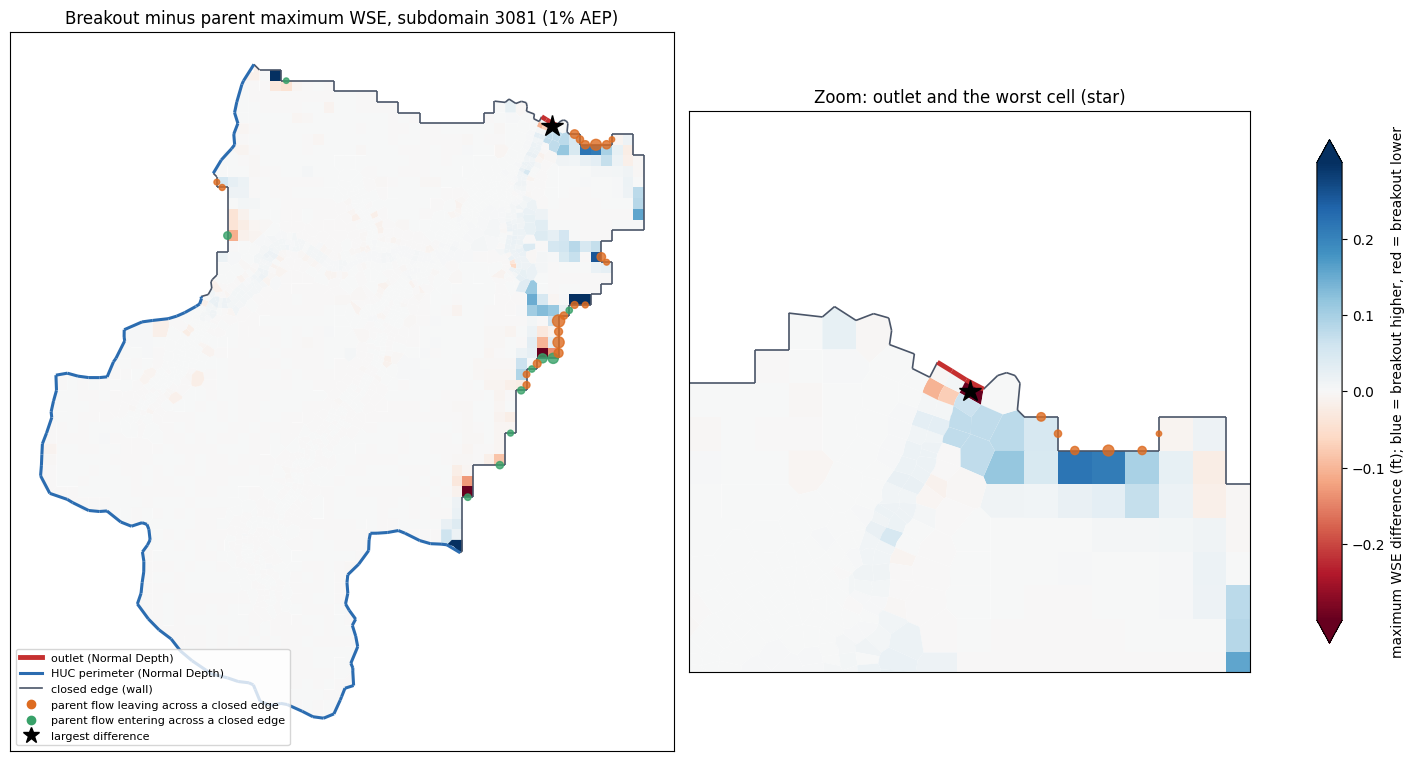

In [14]:
polys = HdfMesh.get_mesh_cell_polygons(child_hdf)
polys = polys[polys["cell_id"] < child_geometry.cell_count].set_index("cell_id").sort_index()
verts = [np.asarray(g.exterior.coords) for g in polys.geometry]
fig, (ax, zoom) = plt.subplots(1, 2, figsize=(15, 7.5), constrained_layout=True,
                               gridspec_kw={"width_ratios": [1.35, 1]})
norm = TwoSlopeNorm(vmin=-0.3, vcenter=0.0, vmax=0.3)
for axis in (ax, zoom):
    pc = PolyCollection(verts, array=cells["wse_diff_ft"].to_numpy(), cmap="RdBu", norm=norm,
                        edgecolors="none")
    axis.add_collection(pc)
    for name, colour, width in (("closed", "#4A5568", 1.2), ("HUC perimeter", "#2B6CB0", 2.2),
                                ("outlet", "#C53030", 3.5)):
        g = seg(edges.face[edges.kind == name])
        for part in g.geoms:
            axis.plot(*np.asarray(part.coords).T, color=colour, linewidth=width, solid_capstyle="butt")
    exch = edges[(edges.kind == "closed") & (edges.parent_volume_out_ft3.abs() > 2000)]
    axis.scatter(exch.x, exch.y, s=np.sqrt(exch.parent_volume_out_ft3.abs()) / 3,
                 c=np.where(exch.parent_volume_out_ft3 > 0, "#DD6B20", "#38A169"), alpha=0.8, zorder=4)
    axis.plot(worst.x, worst.y, marker="*", color="black", markersize=16, zorder=5)
    axis.set_aspect("equal")
    axis.set_xticks([]); axis.set_yticks([])
x0, y0 = worst.x, worst.y
zoom.set_xlim(x0 - 2500, x0 + 2500); zoom.set_ylim(y0 - 2500, y0 + 2500)
ax.autoscale_view()
ax.set_title(f"Breakout minus parent maximum WSE, subdomain {HEADWATER} (1% AEP)")
zoom.set_title("Zoom: outlet and the worst cell (star)")
cbar = fig.colorbar(pc, ax=[ax, zoom], shrink=0.7, extend="both")
cbar.set_label("maximum WSE difference (ft); blue = breakout higher, red = breakout lower")
from matplotlib.lines import Line2D
handles = [Line2D([], [], color="#C53030", lw=3.5, label="outlet (Normal Depth)"),
           Line2D([], [], color="#2B6CB0", lw=2.2, label="HUC perimeter (Normal Depth)"),
           Line2D([], [], color="#4A5568", lw=1.2, label="closed edge (wall)"),
           Line2D([], [], marker="o", ls="", color="#DD6B20", label="parent flow leaving across a closed edge"),
           Line2D([], [], marker="o", ls="", color="#38A169", label="parent flow entering across a closed edge"),
           Line2D([], [], marker="*", ls="", color="black", markersize=12, label="largest difference")]
ax.legend(handles=handles, loc="lower left", fontsize=8, frameon=True)
fig.savefig(FIG_DIR / "03_wse_difference_map.png", dpi=130)
plt.show()

**Reading the map.**

- Blue cells: the breakout's maximum water surface is higher than the parent's.
- Red cells: it is lower.
- Orange dots: the parent sent water *out* across a closed edge.
- Green dots: water came *in* across a closed edge.
- Dot size scales with the square root of the event volume across that face.

The pattern is the hydraulic signature of the walls.

- **Blue next to orange.** Where the parent let water spill over the divide
  into the neighbouring catchment, the breakout's wall holds it back. Cells
  just inside pond a few hundredths to 0.5 ft higher. The longest such stretch
  is the closed edge east of the outlet, where the parent lost the most water.
- **Red next to green.** Where the parent received water from a neighbour, the
  breakout never gets it, and nearby cells peak lower.
- **Interior.** Away from these edges the differences fall to the
  thousandths of a foot, typical of run-to-run 2D noise.

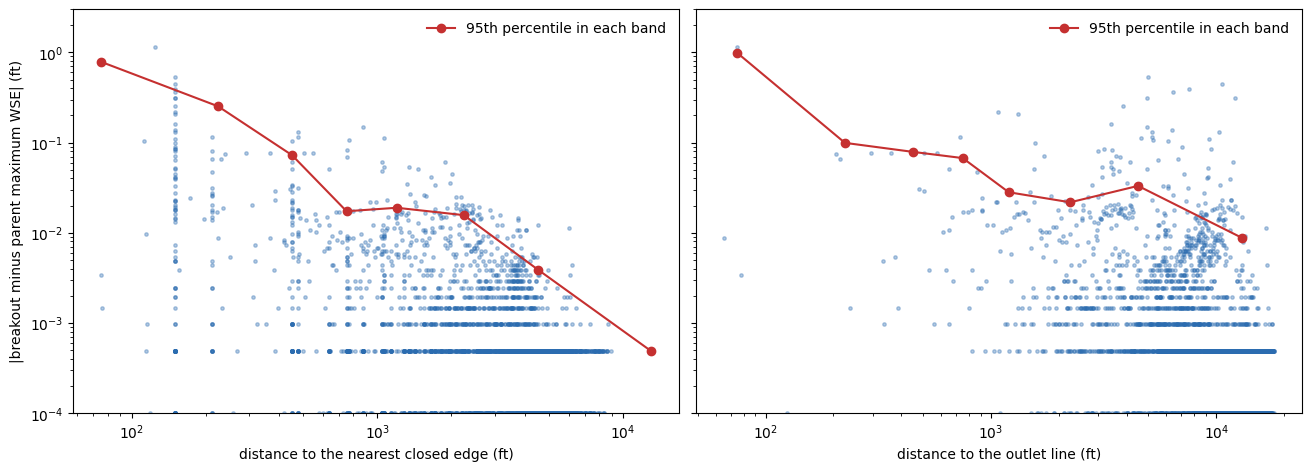

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), constrained_layout=True, sharey=True)
for axis, col, label in ((axes[0], "dist_closed_ft", "distance to the nearest closed edge (ft)"),
                         (axes[1], "dist_outlet_ft", "distance to the outlet line (ft)")):
    axis.scatter(cells[col], absdiff.clip(lower=1e-4), s=6, color="#2B6CB0", alpha=0.35)
    bins = np.array([0, 150, 300, 600, 900, 1500, 3000, 6000, 20000])
    which = np.digitize(cells[col], bins)
    centres = [(bins[i - 1] + bins[i]) / 2 for i in range(1, len(bins))]
    p95 = [absdiff[which == i].quantile(0.95) if (which == i).any() else np.nan for i in range(1, len(bins))]
    axis.plot(centres, p95, color="#C53030", marker="o", label="95th percentile in each band")
    axis.set(xscale="log", yscale="log", xlabel=label, ylim=(1e-4, 3))
    axis.legend(frameon=False)
axes[0].set_ylabel("|breakout minus parent maximum WSE| (ft)")
fig.savefig(FIG_DIR / "04_error_vs_distance.png", dpi=130)
plt.show()

**Error decays with distance from the boundaries that changed.** The 95th
percentile of the absolute difference falls by more than two orders of
magnitude, from about 0.8 ft at the first band to about 0.0005 ft beyond 6,000 ft
from a closed edge. Against distance to the outlet, the decay is weaker
because closed edges run the length of the subdomain. Errors are a local
boundary effect; they do not propagate through the subdomain.

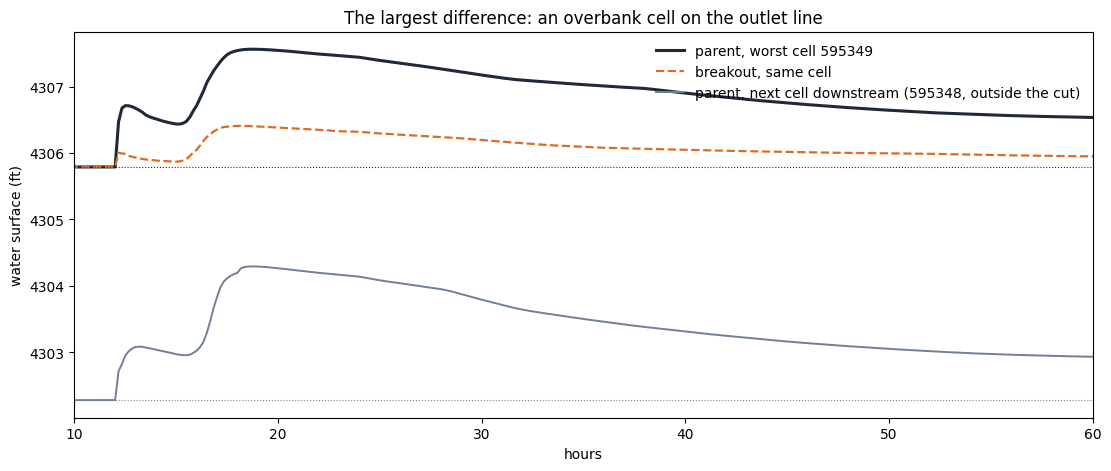

bed elevations: worst cell 4305.79 ft, downstream cell 4302.28 ft, channel stage cell 4297.08 ft


In [16]:
ws = "Results/Unsteady/Output/Output Blocks/Base Output/Unsteady Time Series/2D Flow Areas/SLDR_004/Water Surface"
worst_parent = int(worst.parent_cell)
worst_child = int(np.flatnonzero(parent_of == worst_parent)[0])
downstream_face = next(f for f in outlet_faces if worst_parent in (mesh.cell_0[f], mesh.cell_1[f]))
downstream_cell = int(mesh.cell_1[downstream_face] if mesh.cell_0[downstream_face] == worst_parent
                      else mesh.cell_0[downstream_face])
stage_cell = int(sl.cells_upstream_of(mesh, int(outlet_line["seed"]), outlet_line["downstream"]))
hours = EventReader(parent_1pct, "SLDR_004").seconds() / 3600
with h5py.File(parent_1pct, "r") as f:
    p_worst, p_down = f[ws][:, worst_parent], f[ws][:, downstream_cell]
with h5py.File(child_hdf, "r") as f:
    c_worst = f[ws][:, worst_child]
bed = delivered_geometry.cell_min_elevation
fig, ax = plt.subplots(figsize=(11, 4.6), constrained_layout=True)
ax.plot(hours, p_worst, color="#1F2937", lw=2.2, label=f"parent, worst cell {worst_parent}")
ax.plot(hours, c_worst, color="#DD6B20", lw=1.6, ls="--", label="breakout, same cell")
ax.plot(hours, p_down, color="#718096", lw=1.4, label=f"parent, next cell downstream ({downstream_cell}, outside the cut)")
for cell, colour in ((worst_parent, "#1F2937"), (downstream_cell, "#718096")):
    ax.axhline(bed[cell], color=colour, lw=0.8, ls=":")
ax.set(xlim=(10, 60), xlabel="hours", ylabel="water surface (ft)",
       title="The largest difference: an overbank cell on the outlet line")
ax.legend(frameon=False, loc="upper right")
fig.savefig(FIG_DIR / "05_worst_cell_series.png", dpi=130)
plt.show()
print(f"bed elevations: worst cell {bed[worst_parent]:.2f} ft, downstream cell {bed[downstream_cell]:.2f} ft, "
      f"channel stage cell {bed[stage_cell]:.2f} ft")

**The largest difference is a local outfall control, not a misplaced split
line.** The worst cell lies on the outlet line itself, 75 ft from it and 125 ft
from a closed edge.

- **Where it sits.** Two of the outlet line's three faces cross the channel at
  the bed, near 4,297 ft. The third face crosses an overbank cell whose bed is
  4,305.8 ft, 8.7 ft higher.
- **The parent.** That cell drains over its downstream face as a free outfall:
  the next cell downstream, outside the cut, stays more than 3 ft lower
  throughout. Flow over the face is controlled by the face's own sill, and the
  cell ponds 0.7 to 1.75 ft deep for days.
- **The breakout.** That face is part of the Normal Depth line, so HEC-RAS
  assigns its outflow from the friction slope fitted to the channel (0.0063).
  The overbank cell therefore drains more freely, and its maximum water surface
  is 1.15 ft lower.

The channel itself is unaffected, as the rating below shows. A placement that
ends the outlet line at the channel banks, leaving the perched overbank face
closed, would remove this. It is a refinement of BC line placement, not of the
split-line search.

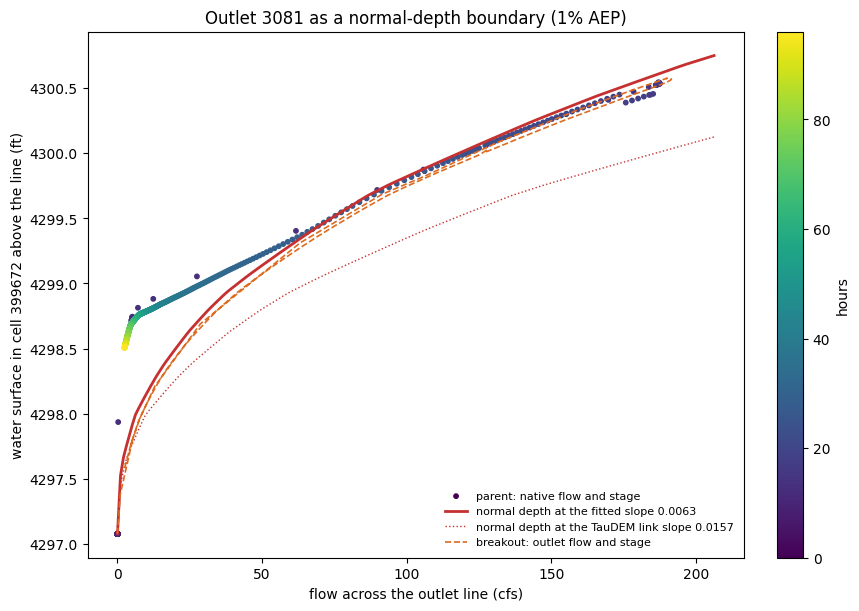

,event,walk_step,best_slope,rmse_ft,peak_error_ft,loop_ft,reverse_fraction,outflow_share
14883,1pct,4,0.0063,0.1747,0.0783,0.1142,0.0,0.9263
42071,0_2pct,4,0.0071,0.1031,0.3216,0.1577,0.0,0.9184


In [17]:
reader = EventReader(parent_1pct, "SLDR_004")
ids, flow = reader.series("Face Flow", outlet_line["faces"])
col = {int(f): i for i, f in enumerate(ids)}
oriented = flow[:, [col[int(f)] for f in outlet_line["faces"]]] * np.asarray(outlet_line["signs"])
parent_q = oriented.sum(axis=1)
with h5py.File(parent_1pct, "r") as f:
    parent_stage = f[ws][:, stage_cell]
child_stage_cell = int(np.flatnonzero(parent_of == stage_cell)[0])
with h5py.File(child_hdf, "r") as f:
    child_stage = f[ws][:, child_stage_cell]
child_h, child_q = _bc_flow(child_hdf, [OUTLET_BC])
child_q = np.interp(hours, child_h, child_q)
tables = face_tables(parent_1pct, "SLDR_004", outlet_line["faces"])
criteria = search.criteria
grid, k = sl.stage_grid(float(bed[stage_cell]), lambda z: sl.conveyance(tables, outlet_line["faces"], z, mesh.length),
                        step=criteria.stage_step_ft, span=criteria.stage_span_ft)
row = search.split_lines.set_index("split_line_id").loc[int(HEADWATER)]
slope = float(row[f"best_slope_{event}"])
q_grid = np.linspace(0, parent_q.max() * 1.1, 200)
nd_stage = sl.normal_depth_stage(q_grid, grid, k, slope)
link_stage = sl.normal_depth_stage(q_grid, grid, k, float(row["link_slope"]))
fig, ax = plt.subplots(figsize=(8.5, 6), constrained_layout=True)
sc = ax.scatter(parent_q, parent_stage, c=hours, cmap="viridis", s=10, label="parent: native flow and stage")
ax.plot(q_grid, nd_stage, color="#C53030", lw=2, label=f"normal depth at the fitted slope {slope:.4f}")
ax.plot(q_grid, link_stage, color="#C53030", lw=1, ls=":", label=f"normal depth at the TauDEM link slope {row['link_slope']:.4f}")
ax.plot(child_q, child_stage, color="#DD6B20", lw=1.2, ls="--", label="breakout: outlet flow and stage")
ax.set(xlabel="flow across the outlet line (cfs)", ylabel=f"water surface in cell {stage_cell} above the line (ft)",
       title=f"Outlet {HEADWATER} as a normal-depth boundary (1% AEP)")
fig.colorbar(sc, ax=ax, label="hours")
ax.legend(frameon=False, loc="lower right", fontsize=8)
fig.savefig(FIG_DIR / "06_outlet_rating.png", dpi=130)
plt.show()
fit = search.candidates[(search.candidates.split_line_id == int(HEADWATER)) & search.candidates.chosen]
display(fit[["event", "walk_step", "best_slope", "rmse_ft", "peak_error_ft", "loop_ft", "reverse_fraction",
             "outflow_share"]].round(4))

**The outlet as a normal-depth boundary.** The dots are the parent's own native
flow across the split line, plotted against the water surface in the cell above
it and coloured by time. The red curve is the normal-depth rating the search
fitted from the face property tables at the best single slope; the orange
dashes are the breakout.

- **The fit holds where it matters.** Above roughly 50 cfs, which covers the
  rising limb, the peak and the main recession, the parent's stage-discharge
  pairs lie on the normal-depth curve. The search accepted this line because
  that fit held in **both** events: the table shows RMSE 0.17 ft (1%) and
  0.10 ft (0.2%), no reverse flow, and 92% to 93% of the contributing area's
  outflow crossing the line. The breakout's outlet follows the same curve, so
  its peak and timing match.
- **The fitted slope, not the terrain slope.** The TauDEM link slope (dotted)
  would put the peak stage about 0.4 ft too low. The 100 ft DEM averages the
  channel bed slope over a reach steeper than the hydraulic control at this
  section.
- **What normal depth cannot represent.** On the long low-flow tail, the
  parent's stage hangs 0.5 to 0.8 ft above normal depth: downstream storage
  drains slowly and holds the section up. A normal-depth boundary cannot
  reproduce that. Because it happens after the peak, it does not affect maximum
  water surfaces. It would matter for a long-duration or low-flow analysis, and
  it is the reason for the guidance not to use normal-depth breakouts in flat,
  backwater-controlled reaches.

## Findings and limits

**The split.** In HEC-RAS 6.4.1 the search accepted 116 normal-depth split lines
that hold in both the 1% and 0.2% AEP events, nested into 25 tiers. On the
delivered mesh it scored 1,304 pour points (54,376 scored steps and events) in
about half an hour. Most candidates fail on outflow share or slope ratio. A
line placed where the channel is not yet carrying its catchment's flow, or
where the water surface slope departs from the bed slope, is rejected, which is
what a normal-depth boundary requires.

**The headwater breakout** reproduces the parent closely. It has 2,592 parent
cells over 5.9 sq mi and was cut, preprocessed and run in 6.4.1 at the
parent's 15 s step. Against the parent's 1% AEP run:

- **Maximum water surface:** within 0.0005 ft at the median and 0.017 ft at the
  95th percentile. Only 22 of 2,592 cells differ by more than 0.1 ft. The wet
  extent is identical.
- **Outlet:** NSE 0.9994 against the parent's native flow across the same
  faces; peak +2.1%, volume +2.0%.

**Where the breakout differs, and why (section 9).** Every difference traces to
one of the two boundaries the cut introduces.

- **Closed edges that were slightly open in the parent.** Rain-on-grid sheet
  flow crossed the terrain divide: 2.6% of the outlet volume out, 0.8% in.
  Walling those faces raises maximum water surfaces just inside where the parent
  spilled out (up to +0.53 ft), and lowers them where the parent received water.
  The effect stays within a few hundred feet of the edge. Cells more than 900 ft
  from a closed edge (85% of the subdomain) match to 0.009 ft at the 95th
  percentile.
- **One overbank face on the outlet line.** The line's third face crosses a
  perched overbank cell 8.7 ft above the channel bed. The parent drains it as a
  free outfall over the face's sill; as part of the Normal Depth line it drains
  more freely and peaks 1.15 ft lower. This is the single largest difference.
  It would be removed by ending the outlet line at the channel banks.
- **The channel itself.** At the outlet section the channel follows the fitted
  normal-depth rating through the rise, peak and main recession. On the
  low-flow tail the parent's downstream storage holds the stage 0.5 to 0.8 ft
  above normal depth. A normal-depth boundary cannot represent that tail.

**Walls or closed-edge outflow.** The optional closed-edge outflow
(`closed_edge_outflow=True`, Normal Depth at 0.00033, kept 2 cells from other BC
lines) was also run on this headwater in HEC-RAS 6.4.1. It released more than twice
the parent's net exchange across those edges and drained a pond held against the
divide. Maximum WSE agreement got worse (p95 0.032 ft, p99 0.42 ft, max 2.98 ft;
outlet volume -1.8%), so this example keeps the walls. Turn it on only where the
parent shows mostly one-way spill across a divide with no ponded storage against
it.

**Why the version and the time step matter.**

- **Version.** Running in the delivered version keeps the delivered mesh and
  its results comparable cell for cell. An earlier 6.6 run of this workflow
  first had to re-mesh the parent, because 6.6 rejects 48 cells with more than
  eight sides; it reached p95 0.018 ft and outlet NSE 0.89.
- **Time step.** Holding the child at the parent's shortest step matters as
  much. With the inherited Courant-adaptive step, a headwater differed by up to
  3.1 ft (p95 0.67 ft): the parent's step is forced down by its most restrictive
  cells elsewhere in the HUC, which a small child never sees.

**What this does not show.** The tiered run of the whole HUC, with hydrograph
hand-off into downstream subdomains, is implemented (`compute_subdomains`) but
is not run here.

**Limits of this release:**

- feet models only;
- the exact-cell cut is qualified for HEC-RAS 6.4.1 and 6.6;
- subdomains with holes, more than one part, or a structure on a split line
  are refused at planning;
- the inflow hand-off rewrites the downstream inline hydrograph and
  preprocesses again.

**Roadmap:**

- end outlet lines at the channel banks when an end face is a perched
  overbank sill;
- an isolated subdomain around a project point or polygon, with its
  downstream and upstream boundary lines found automatically;
- the full-HUC tiered run with a parity table, on the fleet;
- interior subdomains with holes;
- SI units.